In [ ]:
import pandas as pd
import numpy as np
import ast
from collections import Counter
from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_excel("PERCEPT.xlsx")
df.head()

,Text,Source,Topic,Platform,Words,POS,Positions,To Check,Result
0,سلام،اگر دیجی کالا محصولاتی مثل lexar professi...,MirasOpinion,برند و کسب‌وکار,Digikala,"['lexar', 'professional', '256GB', '540mb\\s',...","['PROPN', 'PROPN', 'NUM', 'SYM', 'NOUN']","['initial', 'initial', 'initial', 'medial', 'm...",NaN,"[{'word': 'lexar', 'upos': 'PROPN'}, {'word': ..."
1,با سلام خدمت دوستان من خودم M9 دارم و این یه چ...,MirasOpinion,برند و کسب‌وکار,Digikala,['M9'],['PROPN'],['initial'],NaN,"[{'word': 'M9', 'upos': 'PROPN'}]"
2,سلام دوستان.... من اینو خریدم چند ماه پیش ......,MirasOpinion,برند و کسب‌وکار,Digikala,"['vob', 'mpeg', 'هنگ']","['NOUN', 'NOUN', 'VERB']","['medial', 'medial', 'medial']",NaN,"[{'word': 'vob', 'upos': 'NOUN'}, {'word': 'mp..."
3,سلام این محصول رو امروز تهیه کردم البته به ع...,MirasOpinion,برند و کسب‌وکار,Digikala,"['wifi', 'hp', 'Device', 'Manager', 'Advanced'...","['NOUN', 'PROPN', 'NOUN', 'NOUN', 'ADJ', 'NOUN...","['medial', 'medial', 'medial', 'final', 'final...",NaN,"[{'word': 'wifi', 'upos': 'NOUN'}, {'word': 'h..."
4,متاسفانه برنامه ی دستگاه کاملا چینی هست که یه ...,MirasOpinion,برند و کسب‌وکار,Digikala,['اکانت'],['NOUN'],['initial'],NaN,"[{'word': 'اکانت', 'upos': 'NOUN'}]"


In [ ]:
df = df[df["Topic"] != "other"]

In [ ]:
topicDict = {
    "برند و کسب‌وکار": "Brand & Business",
    "جامعه و هویت": "Society & Identity",
    "رویدادهای جاری و اخبار": "Current Events & News",
    "سبک زندگی و علایق شخصی": "Lifestyle & Personal Interests",
    "صنعت و تجارت": "Industry & Commerce",
    "موضوعات مختص پلتفرم": "Platform-Specific & Meta Topics",
    "هنر، سرگرمی و فرهنگ": "Arts, Entertainment & Culture"
}

In [ ]:
df["English Topic"] = np.nan
df["Platform"] = df["Platform"].replace({"Twitter": "Twitter (X)"})

In [ ]:
for index, row in df.iterrows():
  df.at[index, "English Topic"] = topicDict[row["Topic"]]

/tmp/ipykernel_1081/3498505403.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Brand & Business' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.at[index, "English Topic"] = topicDict[row["Topic"]]


In [ ]:
df.head()

,Text,Source,Topic,Platform,Words,POS,Positions,To Check,Result,English Topic
0,سلام،اگر دیجی کالا محصولاتی مثل lexar professi...,MirasOpinion,برند و کسب‌وکار,Digikala,"['lexar', 'professional', '256GB', '540mb\\s',...","['PROPN', 'PROPN', 'NUM', 'SYM', 'NOUN']","['initial', 'initial', 'initial', 'medial', 'm...",NaN,"[{'word': 'lexar', 'upos': 'PROPN'}, {'word': ...",Brand & Business
1,با سلام خدمت دوستان من خودم M9 دارم و این یه چ...,MirasOpinion,برند و کسب‌وکار,Digikala,['M9'],['PROPN'],['initial'],NaN,"[{'word': 'M9', 'upos': 'PROPN'}]",Brand & Business
2,سلام دوستان.... من اینو خریدم چند ماه پیش ......,MirasOpinion,برند و کسب‌وکار,Digikala,"['vob', 'mpeg', 'هنگ']","['NOUN', 'NOUN', 'VERB']","['medial', 'medial', 'medial']",NaN,"[{'word': 'vob', 'upos': 'NOUN'}, {'word': 'mp...",Brand & Business
3,سلام این محصول رو امروز تهیه کردم البته به ع...,MirasOpinion,برند و کسب‌وکار,Digikala,"['wifi', 'hp', 'Device', 'Manager', 'Advanced'...","['NOUN', 'PROPN', 'NOUN', 'NOUN', 'ADJ', 'NOUN...","['medial', 'medial', 'medial', 'final', 'final...",NaN,"[{'word': 'wifi', 'upos': 'NOUN'}, {'word': 'h...",Brand & Business
4,متاسفانه برنامه ی دستگاه کاملا چینی هست که یه ...,MirasOpinion,برند و کسب‌وکار,Digikala,['اکانت'],['NOUN'],['initial'],NaN,"[{'word': 'اکانت', 'upos': 'NOUN'}]",Brand & Business


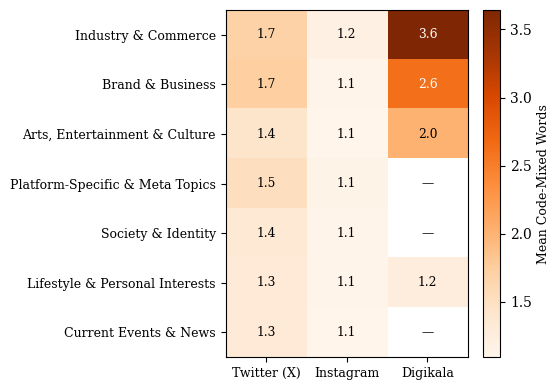

In [ ]:
# ---------------------------------------------------------
# Compute average number of code-mixed words per utterance
# ---------------------------------------------------------

df["Words"] = df["Words"].apply(ast.literal_eval)
df["Mixing Count"] = df["Words"].apply(len)

summary = (
    df.groupby(["Platform", "English Topic"])
      .agg(
          AvgMixing=("Mixing Count", "mean"),
          N=("Mixing Count", "size")
      )
      .reset_index()
)

# ---------------------------------------------------------
# Pivot for heatmap
# ---------------------------------------------------------

heatmap = summary.pivot(
    index="English Topic",
    columns="Platform",
    values="AvgMixing"
)

# Reorder platforms
platform_order = ["Twitter (X)", "Instagram", "Digikala"]
heatmap = heatmap[platform_order]

# Sort topics by overall average
topic_order = (
    summary.groupby("English Topic")["AvgMixing"]
           .mean()
           .sort_values(ascending=False)
           .index
)

heatmap = heatmap.loc[topic_order]

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(5.5, 4))

# Copy colormap so NaNs can be shown in white
cmap = plt.cm.Oranges.copy()
cmap.set_bad(color="white")

# Plot
im = ax.imshow(
    heatmap.values,
    cmap=cmap,
    aspect="auto",
    interpolation="nearest"
)

# Colorbar
cbar = plt.colorbar(im)
cbar.set_label("Mean Code-Mixed Words", fontsize=9)

# Tick labels
ax.set_xticks(np.arange(len(heatmap.columns)))
ax.set_xticklabels(heatmap.columns, rotation=0, ha="center", fontsize=9)

ax.set_yticks(np.arange(len(heatmap.index)))
ax.set_yticklabels(heatmap.index, fontsize=9)

# Threshold for switching text color
vmin = np.nanmin(heatmap.values)
vmax = np.nanmax(heatmap.values)
threshold = (vmin + vmax) / 2

for i in range(len(heatmap.index)):
    for j in range(len(heatmap.columns)):

        value = heatmap.iloc[i, j]

        if pd.isna(value):
            text = "—"
            color = "black"
        else:
            text = f"{value:.1f}"
            color = "white" if value > threshold else "black"

        ax.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            fontsize=8.8,
            color=color
        )

ax.set_xlabel("")
ax.set_ylabel("")

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "DejaVu Serif"]

plt.tight_layout()
plt.savefig("heatmapTopic.pdf", format="pdf", bbox_inches="tight")
plt.show()